# Практическая работа №1. Линейные дискретные системы и преобразование Фурье

Вариант 4

Выполнила: Глебова В.С., группа 3388

Цель работы: изучить математическое описание линейных дискретных систем и ДПФ периодических последовательностей и последовательностей конечной длины.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True

## Часть 1

### Исходные данные

In [2]:
v = 4

b0 = 0.5 + 0.02 * v
b1 = b0 * (-1) ** (v + 1) * (0.9822 + 0.0178 * v)
b2 = b0 * (0.8 + 0.2 * (v % 5))
a0 = 1
a1 = (-1) ** v * (0.7778 + 0.025 * v)
a2 = 0.64 + 0.006 * v

N1 = v % 10 + 20   # длина ИХ
N2 = v % 10 + 30   # длина воздействия
fd = 1000 * v      # Гц

b = [b0, b1, b2]
a = [a0, a1, a2]

print('b =', np.round(b, 6))
print('a =', np.round(a, 6))
print('N1 =', N1, ' N2 =', N2, ' fd =', fd)

b = [ 0.58     -0.610972  0.928   ]
a = [1.     0.8778 0.664 ]
N1 = 24  N2 = 34  fd = 4000


$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}=\frac{0.58-0.611z^{-1}+0.928z^{-2}}{1+0.8778z^{-1}+0.664z^{-2}}$$

### Пункт 1. Импульсная характеристика

Импульсную характеристику (ИХ) находим как реакцию звена на цифровой единичный импульс $u_0(n)$.

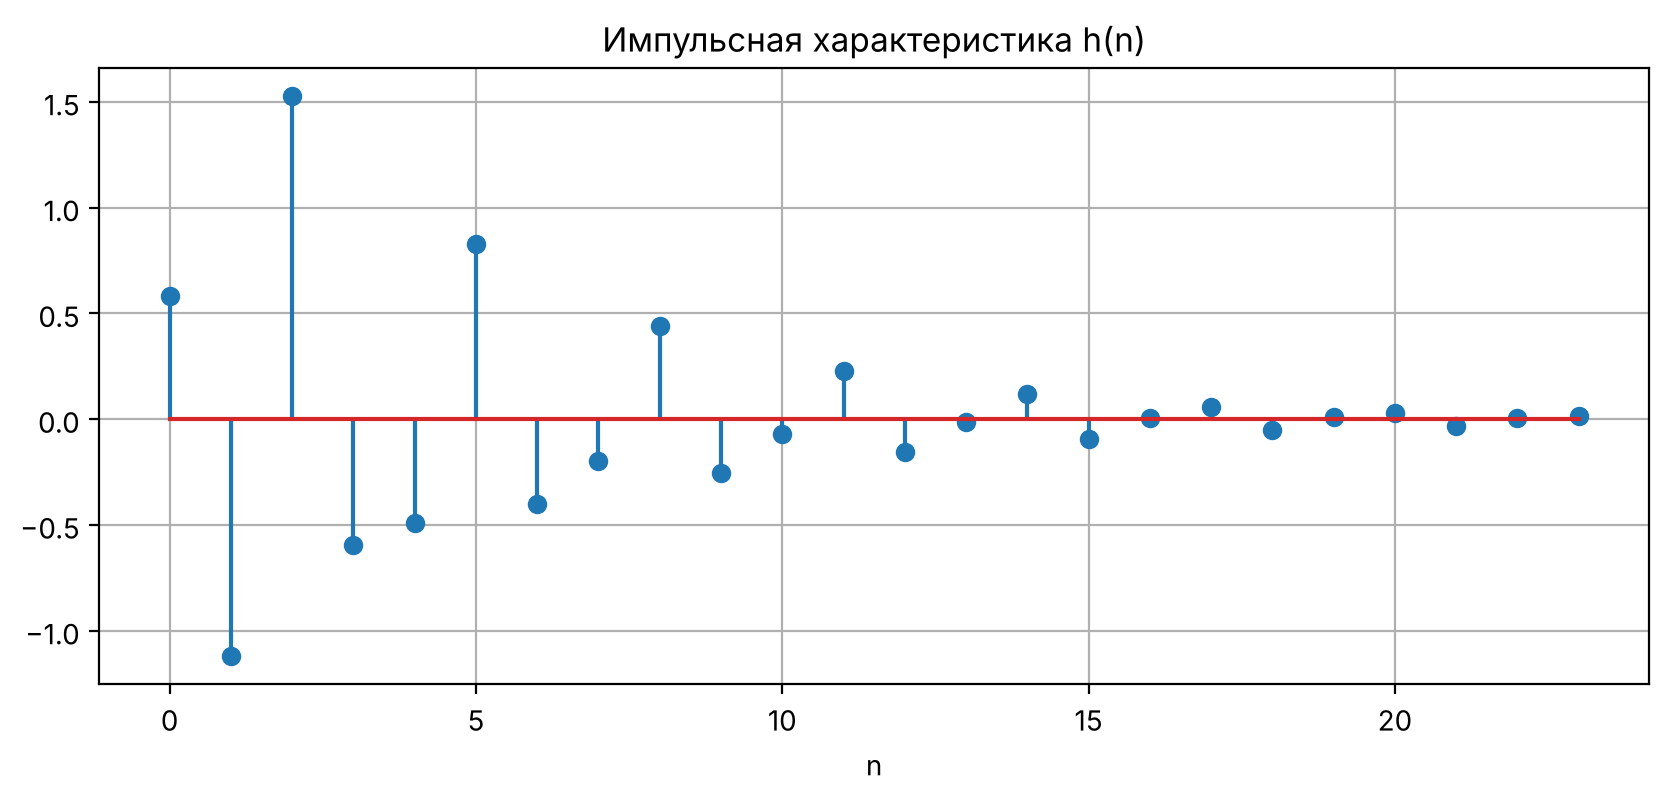

In [3]:
n = np.arange(N1)
d = np.zeros(N1)
d[0] = 1

h = signal.lfilter(b, a, d)

plt.stem(n, h)
plt.title('Импульсная характеристика h(n)')
plt.xlabel('n')
plt.show()

При нулевых начальных условиях ИХ звена 2-го порядка:

$$h(n)=b_0r^n\frac{\sin((n+1)\varphi)}{\sin\varphi}u_1(n)+b_1r^{n-1}\frac{\sin(n\varphi)}{\sin\varphi}u_1(n-1)+b_2r^{n-2}\frac{\sin((n-1)\varphi)}{\sin\varphi}u_1(n-2),$$

где $r=\sqrt{a_2}$, $\cos\varphi=-a_1/(2r)$. Для варианта 4 $r=0.8149$, $\varphi=0.6811\pi$.

Проверим, что формула дает те же значения:

In [4]:
r = np.sqrt(a2)
fi = np.arccos(-a1 / (2 * r))

def g(m):
    return (m >= 0) * r**m * np.sin((m + 1) * fi) / np.sin(fi)

hh = b0 * g(n) + b1 * g(n - 1) + b2 * g(n - 2)
print('r =', round(r, 4), ' fi =', round(fi / np.pi, 4), 'pi')
print(np.allclose(hh, h))

r = 0.8149  fi = 0.6811 pi
True


У рекурсивного звена ИХ бесконечная. Она затухает примерно как $0.815^n$, но до нуля не доходит. Здесь посчитаны только первые $N_1=24$ отсчета.

### Пункт 2. Реакция по формуле свертки

Воздействие: первые 17 отсчетов равны 1, остальные 0.

длина свертки: 57


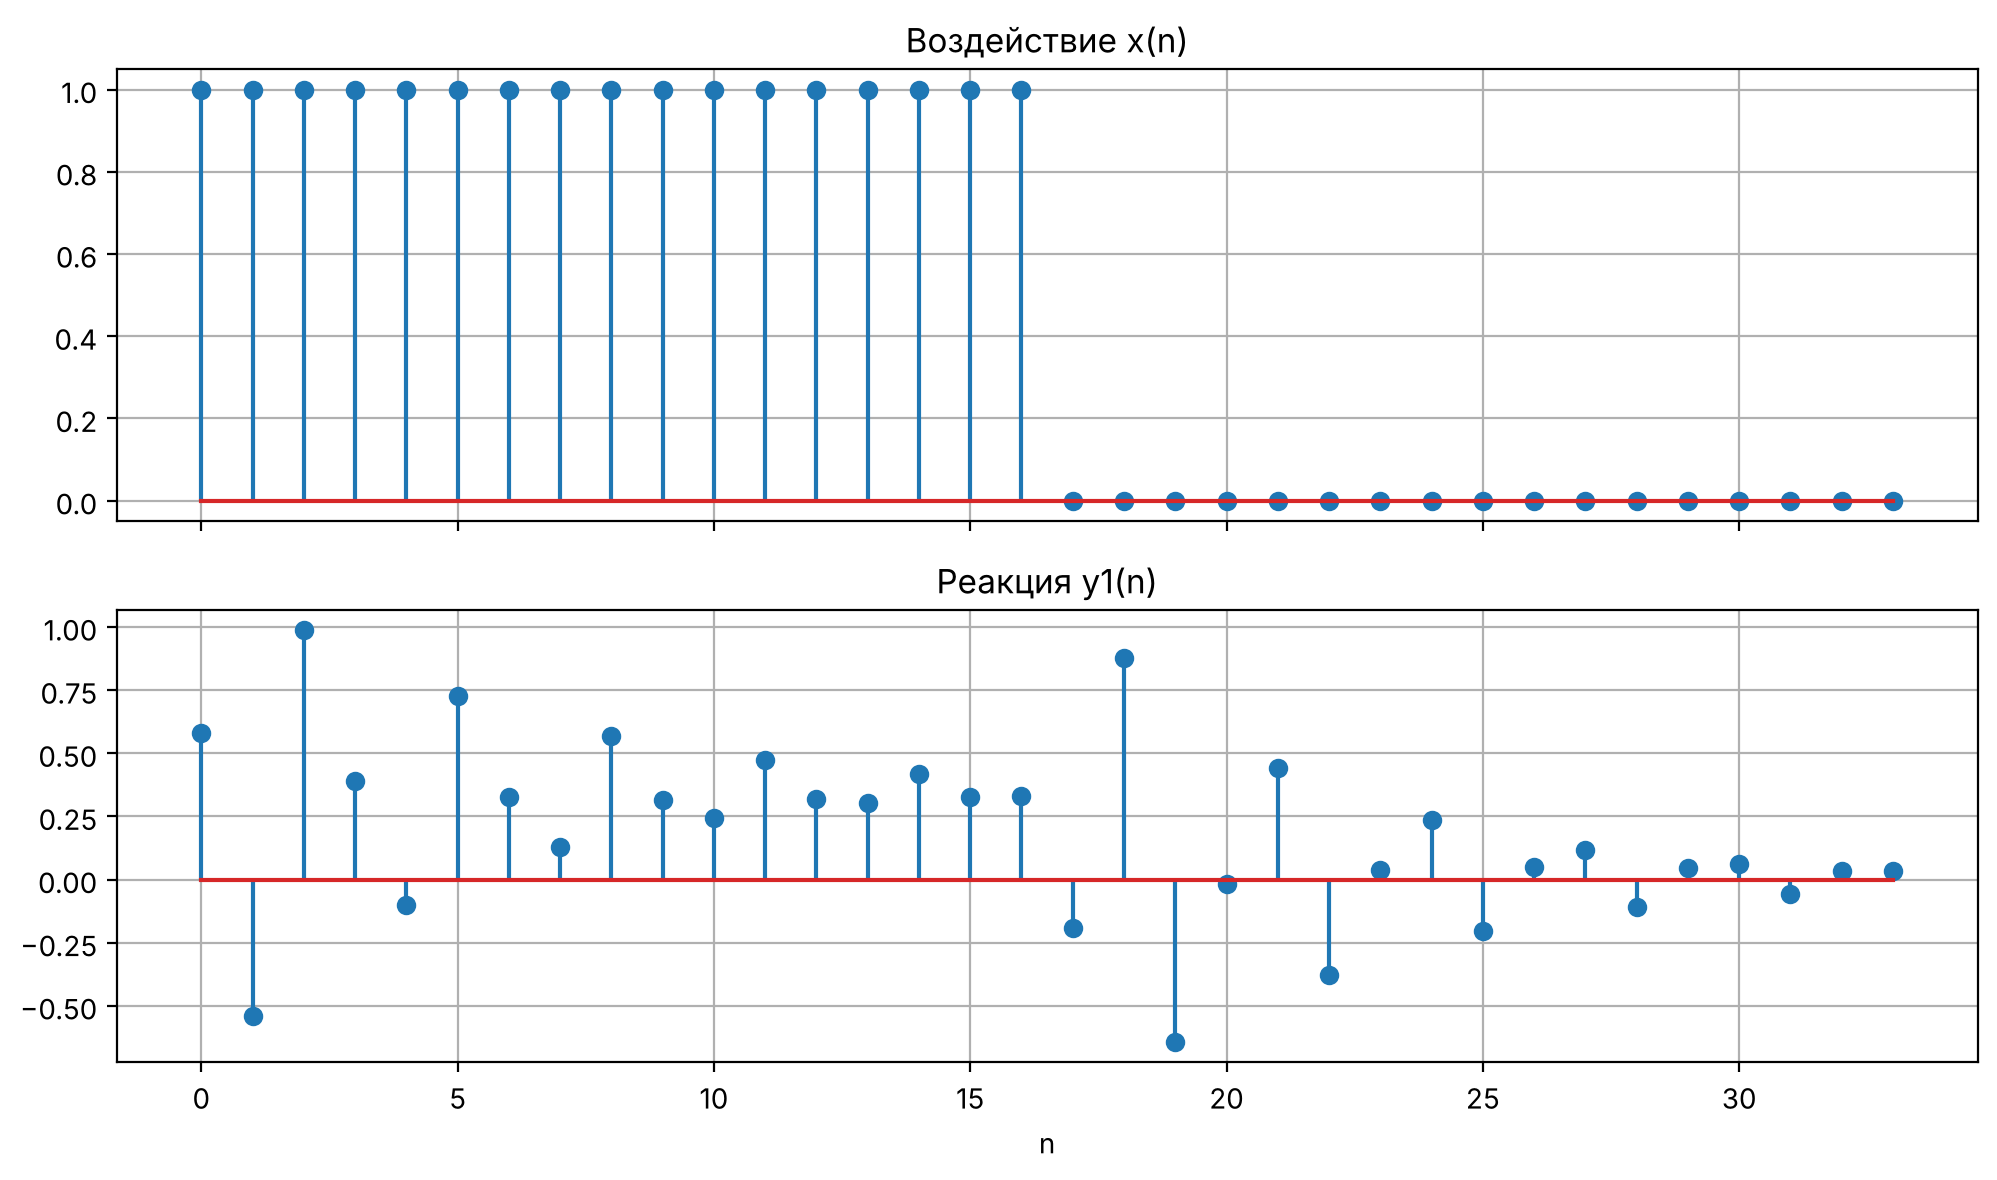

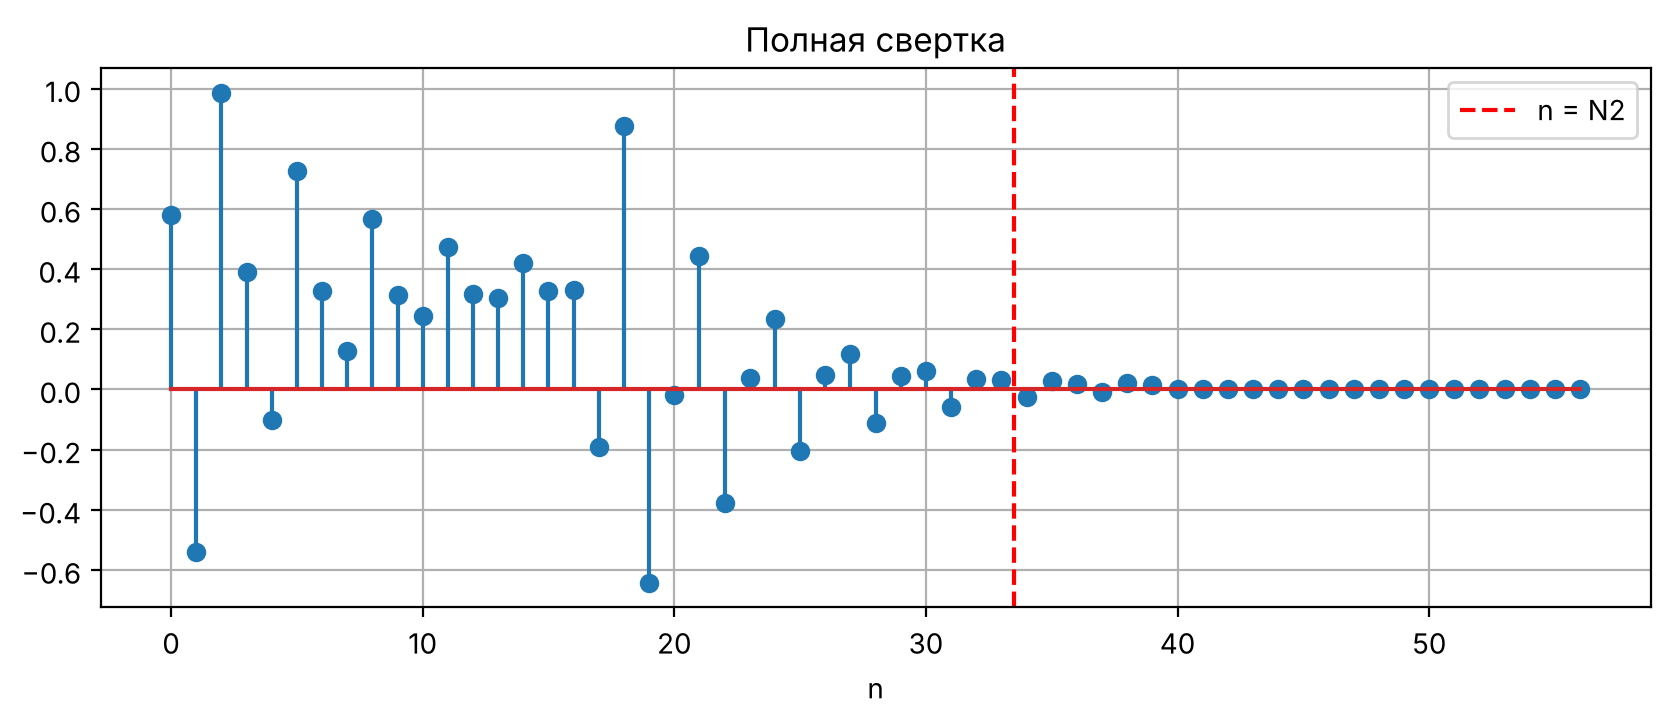

In [5]:
n2 = np.arange(N2)
x = np.zeros(N2)
x[:int(round(N2 / 2))] = 1

yc = np.convolve(x, h)
y1 = yc[:N2]

print('длина свертки:', len(yc))

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].stem(n2, x)
ax[0].set_title('Воздействие x(n)')
ax[1].stem(n2, y1)
ax[1].set_title('Реакция y1(n)')
ax[1].set_xlabel('n')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3.5))
plt.stem(np.arange(len(yc)), yc)
plt.axvline(N2 - 0.5, color='r', ls='--', label='n = N2')
plt.title('Полная свертка')
plt.xlabel('n')
plt.legend()
plt.show()

а) Длина импульса 17 отсчетов.

б) Аналитически длина свертки $N_1+N_2-1=57$. На графике ненулевые значения идут до $n=39$, дальше нули, потому что после 17-го отсчета воздействие нулевое.

в) Свертку ограничивают длиной воздействия, чтобы сравнить ее с реакцией по разностному уравнению, у которой тоже 34 отсчета.

### Пункт 3. Реакция по разностному уравнению

$$y(n)=0.58\,x(n)-0.611\,x(n-1)+0.928\,x(n-2)-0.8778\,y(n-1)-0.664\,y(n-2)$$

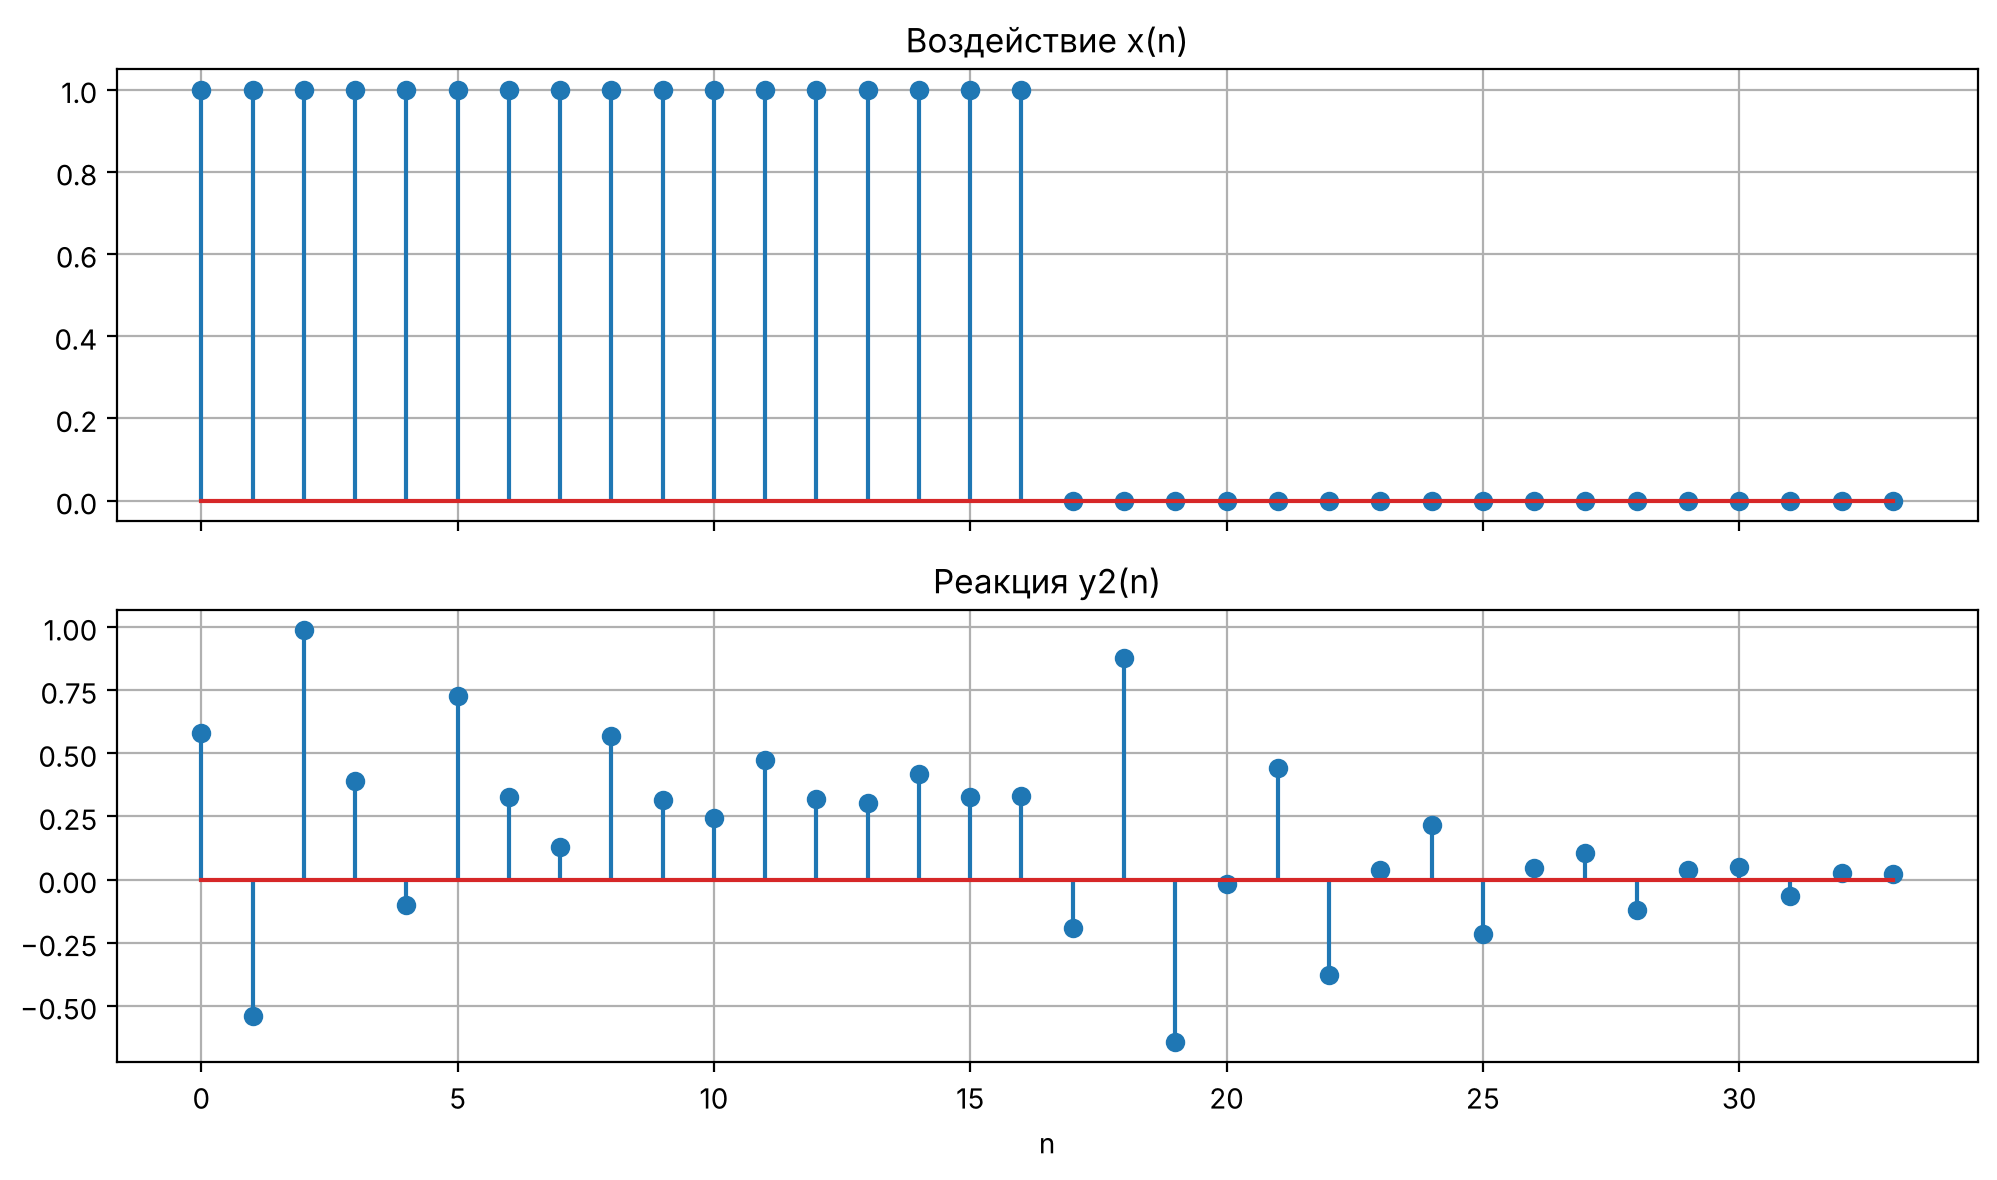

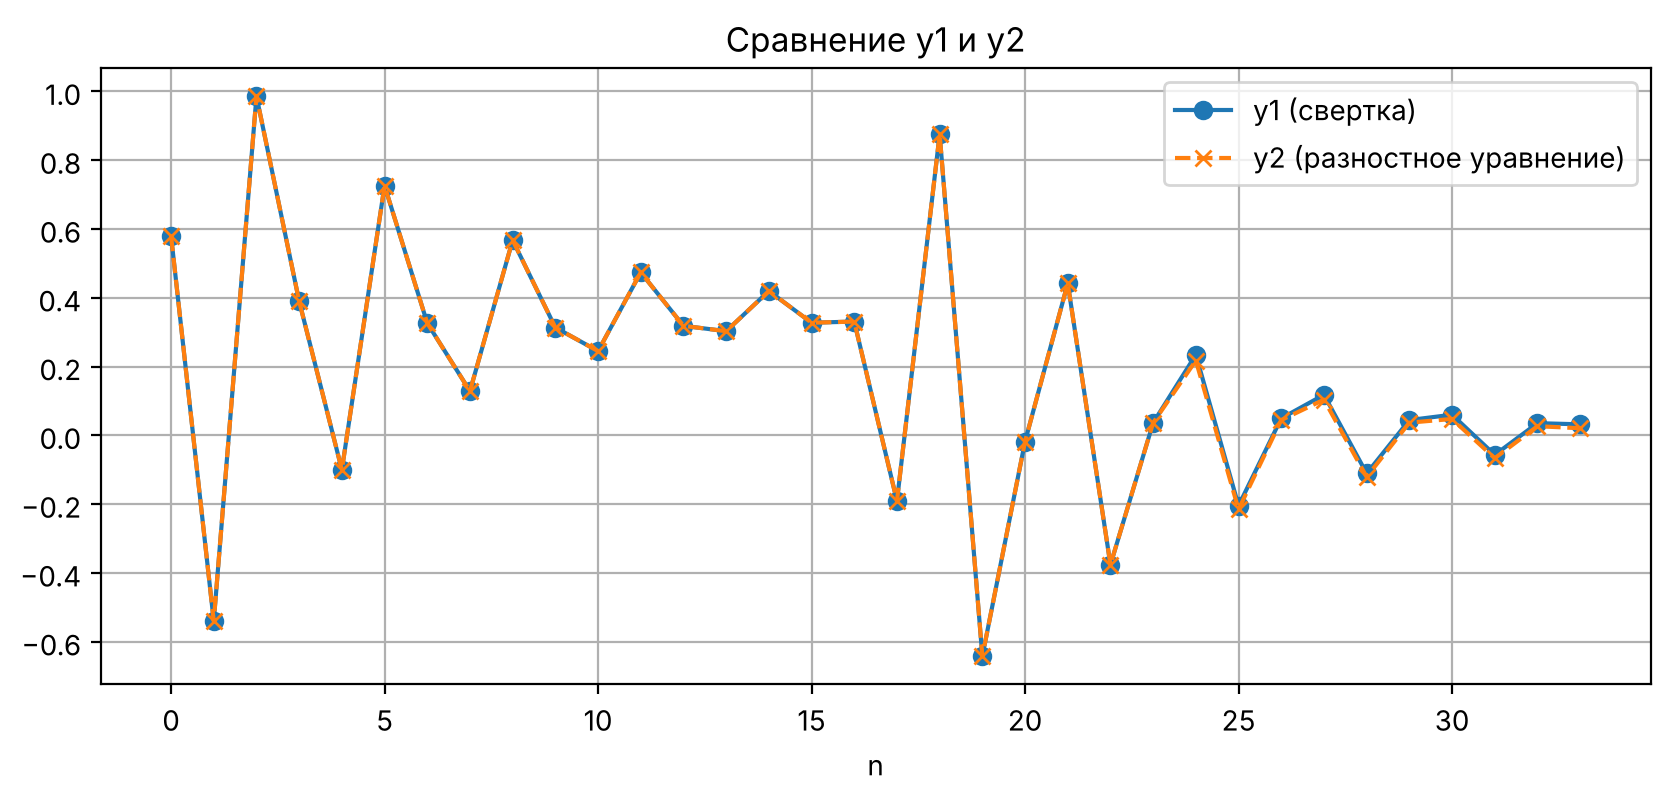

max|y1 - y2| = 0.016795834865878684


In [6]:
y2 = signal.lfilter(b, a, x)

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].stem(n2, x)
ax[0].set_title('Воздействие x(n)')
ax[1].stem(n2, y2)
ax[1].set_title('Реакция y2(n)')
ax[1].set_xlabel('n')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(n2, y1, 'o-', label='y1 (свертка)')
plt.plot(n2, y2, 'x--', label='y2 (разностное уравнение)')
plt.title('Сравнение y1 и y2')
plt.xlabel('n')
plt.legend()
plt.show()

print('max|y1 - y2| =', max(abs(y1 - y2)))

Длина воздействия и реакции одинаковая, 34 отсчета.

Графики $y_1$ и $y_2$ почти совпадают. Небольшая разница (до 0.017) появляется с $n=24$: в свертке ИХ обрезана до 24 отсчетов, а в разностном уравнении такого ограничения нет.

### Пункт 4. Нули и полюсы

In [7]:
z, p, k = signal.tf2zpk(b, a)

print('Нули:')
for i in z:
    print(' ', np.round(i, 4), '=', round(abs(i), 4), '* exp(j', round(np.angle(i) / np.pi, 4), 'pi)')
print('Полюсы:')
for i in p:
    print(' ', np.round(i, 4), '=', round(abs(i), 4), '* exp(j', round(np.angle(i) / np.pi, 4), 'pi)')

Нули:
  (0.5267+1.15j) = 1.2649 * exp(j 0.3633 pi)
  (0.5267-1.15j) = 1.2649 * exp(j -0.3633 pi)
Полюсы:
  (-0.4389+0.6866j) = 0.8149 * exp(j 0.6811 pi)
  (-0.4389-0.6866j) = 0.8149 * exp(j -0.6811 pi)


Нули: $z_{1,2}=0.5267\pm j1.15=1.2649\,e^{\pm j0.3633\pi}$.

Полюсы: $p_{1,2}=-0.4389\pm j0.6866=0.8149\,e^{\pm j0.6811\pi}$.

Модуль $r=\sqrt{x^2+y^2}$, аргумент $\varphi=\mathrm{arctg}(y/x)$, у полюсов $x<0$, поэтому к арктангенсу прибавляется $\pi$. Обратно: $x=r\cos\varphi$, $y=r\sin\varphi$.

$$H(z)=0.58\,\frac{\left(1-1.2649e^{j0.3633\pi}z^{-1}\right)\left(1-1.2649e^{-j0.3633\pi}z^{-1}\right)}{\left(1-0.8149e^{j0.6811\pi}z^{-1}\right)\left(1-0.8149e^{-j0.6811\pi}z^{-1}\right)}$$

### Пункт 5. Карта нулей и полюсов

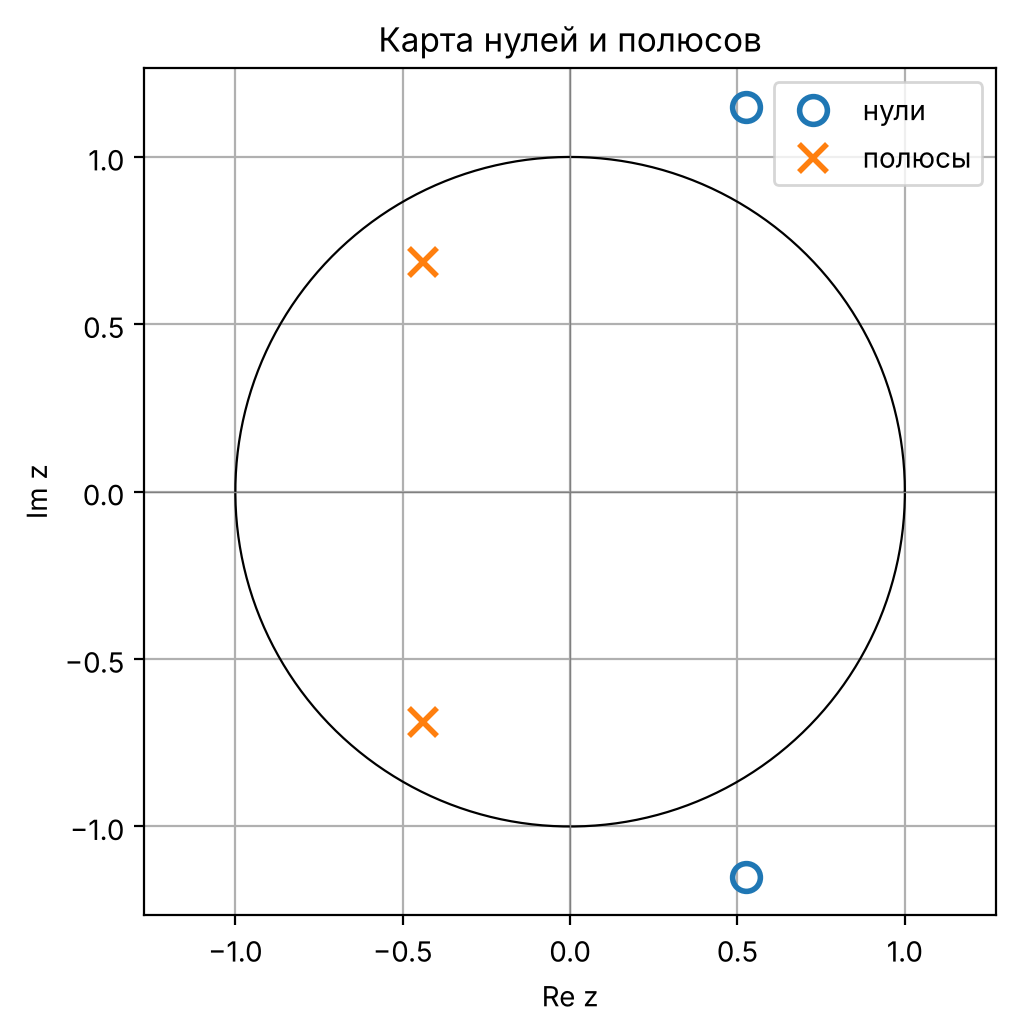

нули: [0.5267+1.15j 0.5267-1.15j]
полюсы: [-0.4389+0.6866j -0.4389-0.6866j]


In [8]:
zz = np.roots(b)
pp = np.roots(a)

t = np.linspace(0, 2 * np.pi, 400)
plt.figure(figsize=(5.5, 5.5))
plt.plot(np.cos(t), np.sin(t), 'k', lw=0.8)
plt.plot(zz.real, zz.imag, 'o', mfc='none', ms=10, mew=2, label='нули')
plt.plot(pp.real, pp.imag, 'x', ms=10, mew=2, label='полюсы')
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.axis('equal')
plt.title('Карта нулей и полюсов')
plt.xlabel('Re z')
plt.ylabel('Im z')
plt.legend()
plt.show()

print('нули:', np.round(zz, 4))
print('полюсы:', np.round(pp, 4))

а) Звено устойчиво, оба полюса внутри единичного круга ($|p|=0.815$). Нули снаружи ($|z|=1.265$), на устойчивость это не влияет.

б) Да, совпадают с п. 4.

### Пункт 6. АЧХ и ФЧХ в шкале нормированных частот

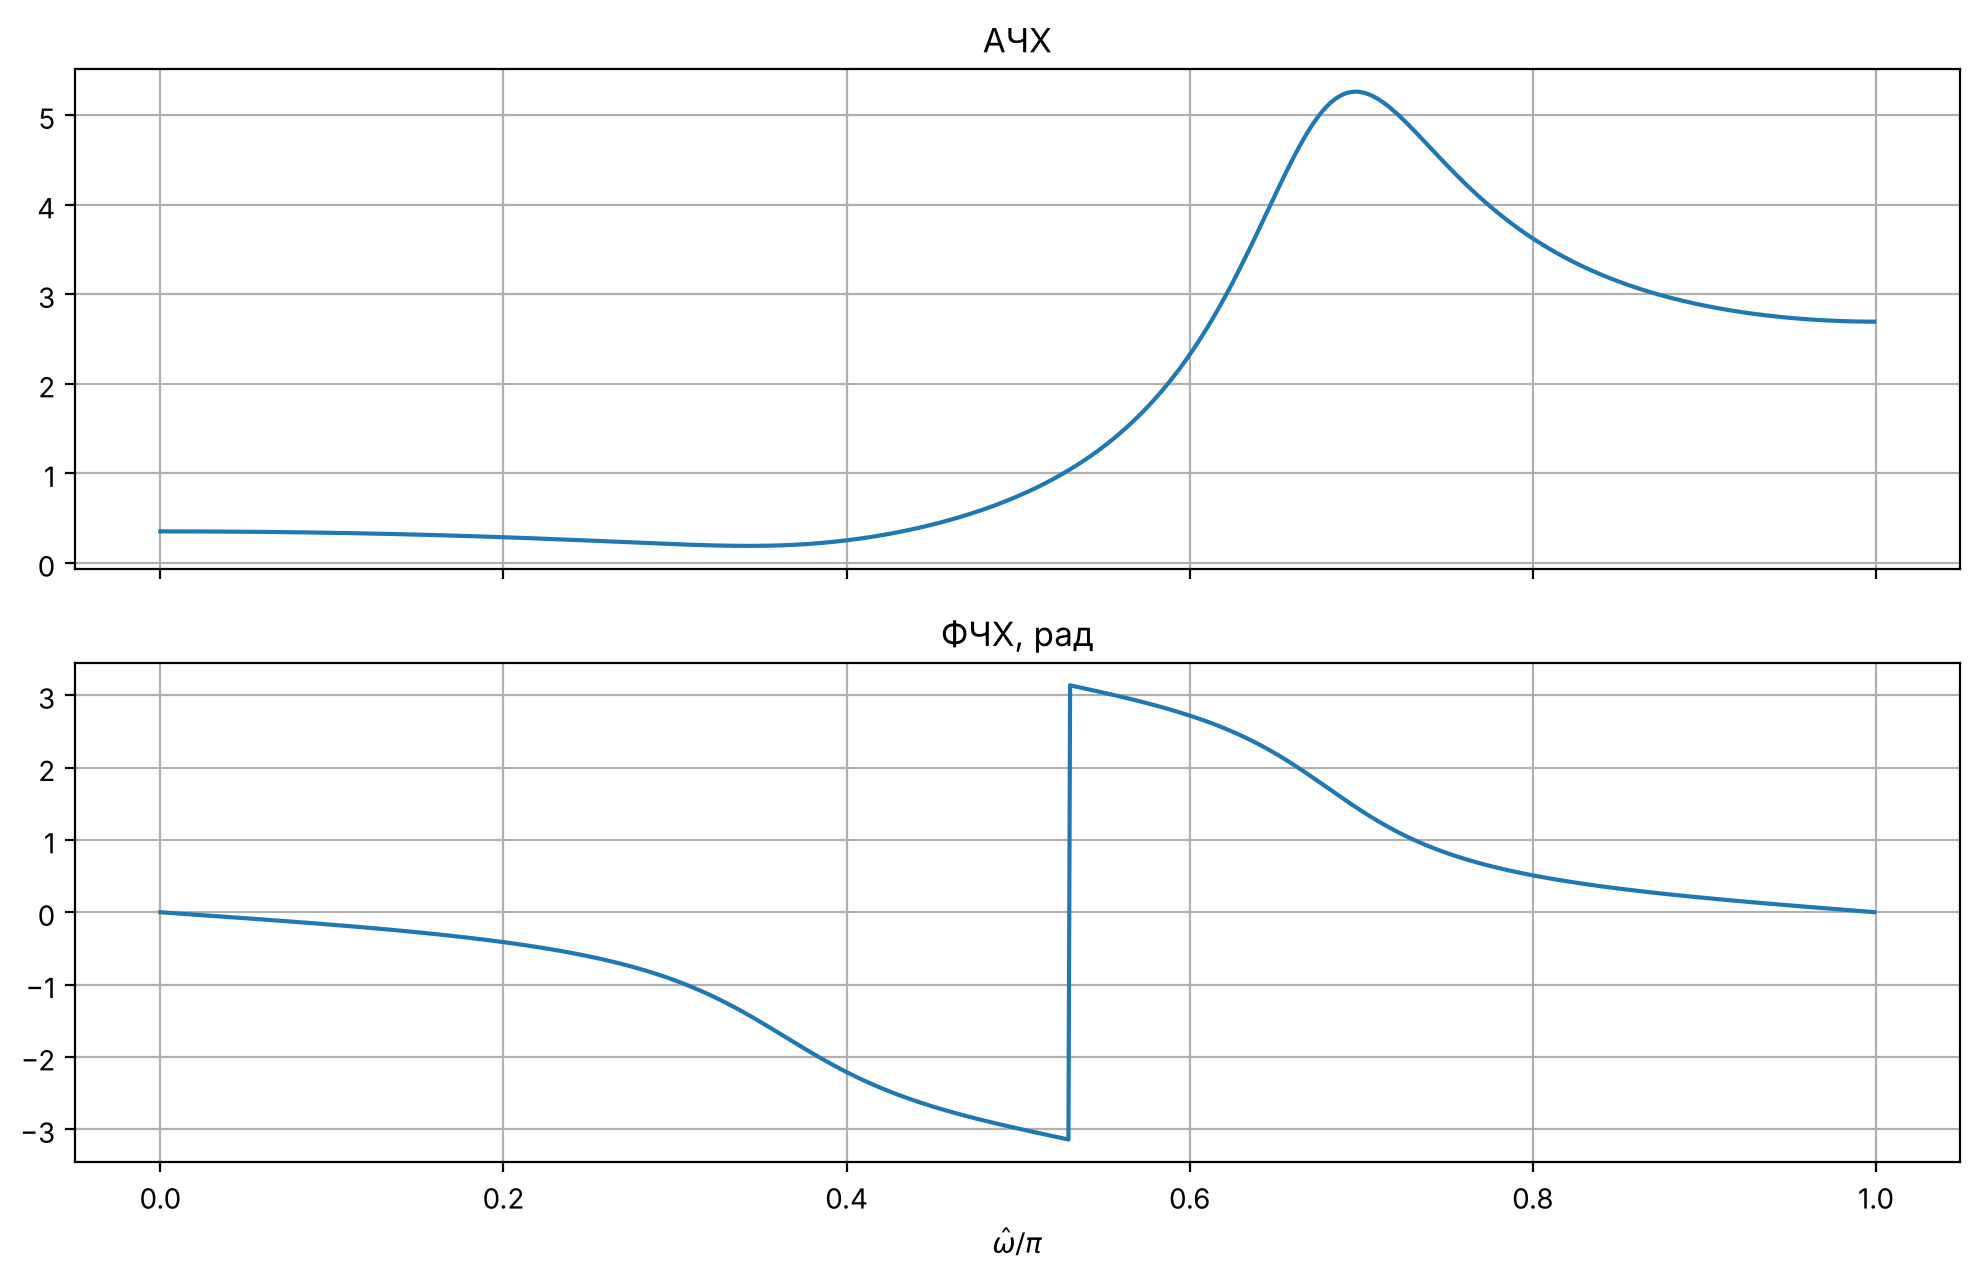

|H| при w=0: 0.353
|H| при w=pi: 2.695
max 5.26 при w = 0.696 pi
min 0.19 при w = 0.343 pi


In [9]:
w, H = signal.freqz(b, a, worN=1024)
ach = abs(H)
fch = np.angle(H)

fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ax[0].plot(w / np.pi, ach)
ax[0].set_title('АЧХ')
ax[1].plot(w / np.pi, fch)
ax[1].set_title('ФЧХ, рад')
ax[1].set_xlabel(r'$\hat\omega/\pi$')
plt.tight_layout()
plt.show()

print('|H| при w=0:', round(ach[0], 3))
print('|H| при w=pi:', round(abs(sum(b[i] * (-1)**i for i in range(3)) / sum(a[i] * (-1)**i for i in range(3))), 3))
i = np.argmax(ach)
j = np.argmin(ach)
print('max', round(ach[i], 2), 'при w =', round(w[i] / np.pi, 3), 'pi')
print('min', round(ach[j], 2), 'при w =', round(w[j] / np.pi, 3), 'pi')

а) Основная полоса $0\leq\hat\omega\leq\pi$.

б) Максимум АЧХ (5.26) при $\hat\omega\approx0.696\pi$, рядом с аргументом полюса $0.681\pi$. Минимум (0.19) при $\hat\omega\approx0.343\pi$, рядом с аргументом нуля $0.363\pi$. Нуль лежит вне единичной окружности, поэтому АЧХ в ноль не обращается.

в) Скачок на $\pi$ бывает там, где АЧХ равна нулю. Здесь таких точек нет. Скачок при $0.53\pi$ равен $2\pi$, он появляется потому, что фаза выводится в пределах от $-\pi$ до $\pi$.

г) Подавлены низкие частоты: $|H(0)|=0.35$, а $|H(\pi)|=2.7$. Поэтому на плоской части импульса реакция колеблется около 0.35, а на фронтах видны всплески.

### Пункт 7. АЧХ и ФЧХ в шкале частот f

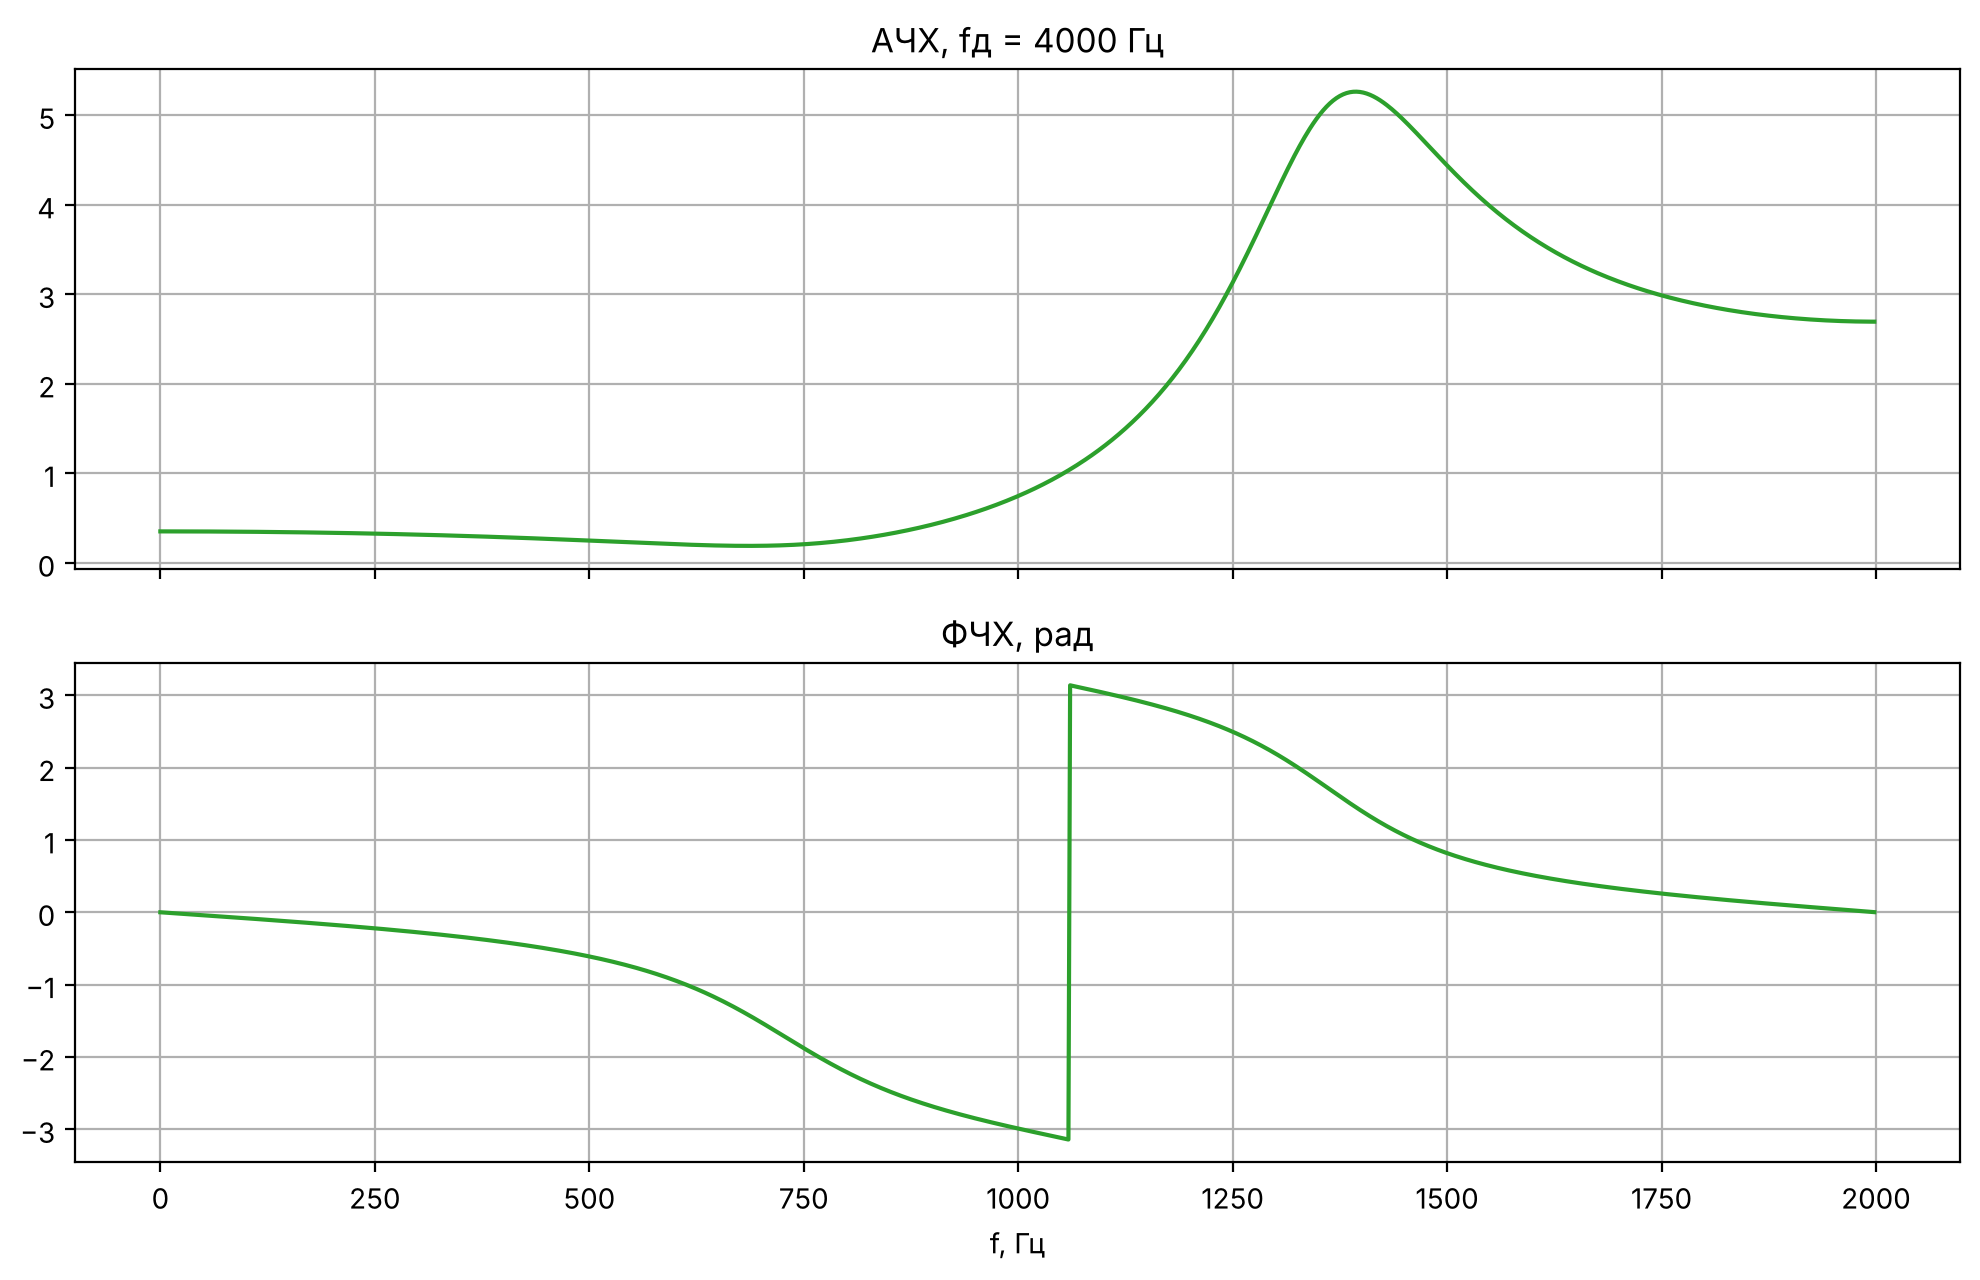

max АЧХ при f = 1393 Гц


In [10]:
f = w * fd / (2 * np.pi)

fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ax[0].plot(f, ach, color='C2')
ax[0].set_title('АЧХ, fд = ' + str(fd) + ' Гц')
ax[1].plot(f, fch, color='C2')
ax[1].set_title('ФЧХ, рад')
ax[1].set_xlabel('f, Гц')
plt.tight_layout()
plt.show()

print('max АЧХ при f =', round(f[i]), 'Гц')

а) Основная полоса $0\leq f\leq f_д/2=2000$ Гц.

б) $f=\hat\omega f_д/(2\pi)$, то есть $\hat\omega=\pi$ соответствует 2000 Гц, а максимум АЧХ при $0.696\pi$ соответствует 1393 Гц.

## Часть 2

### Исходные данные

In [11]:
N = 64
fd2 = 2000 * (v % 5 + 1)
T = 1 / fd2
A1 = 1 + 0.01 * v
A2 = 2 * A1
f1 = fd2 / 8
f2 = 1.5 * f1

print('N =', N, ' fд =', fd2, ' T =', T)
print('A1 =', A1, ' A2 =', A2)
print('f1 =', f1, ' f2 =', f2)

N = 64  fд = 10000  T = 0.0001
A1 = 1.04  A2 = 2.08
f1 = 1250.0  f2 = 1875.0


### Пункт 1. Последовательность x(n)

$$x(nT)=A_1\cos(2\pi f_1nT+\pi/4)+A_2\cos(2\pi f_2nT+\pi/8)$$

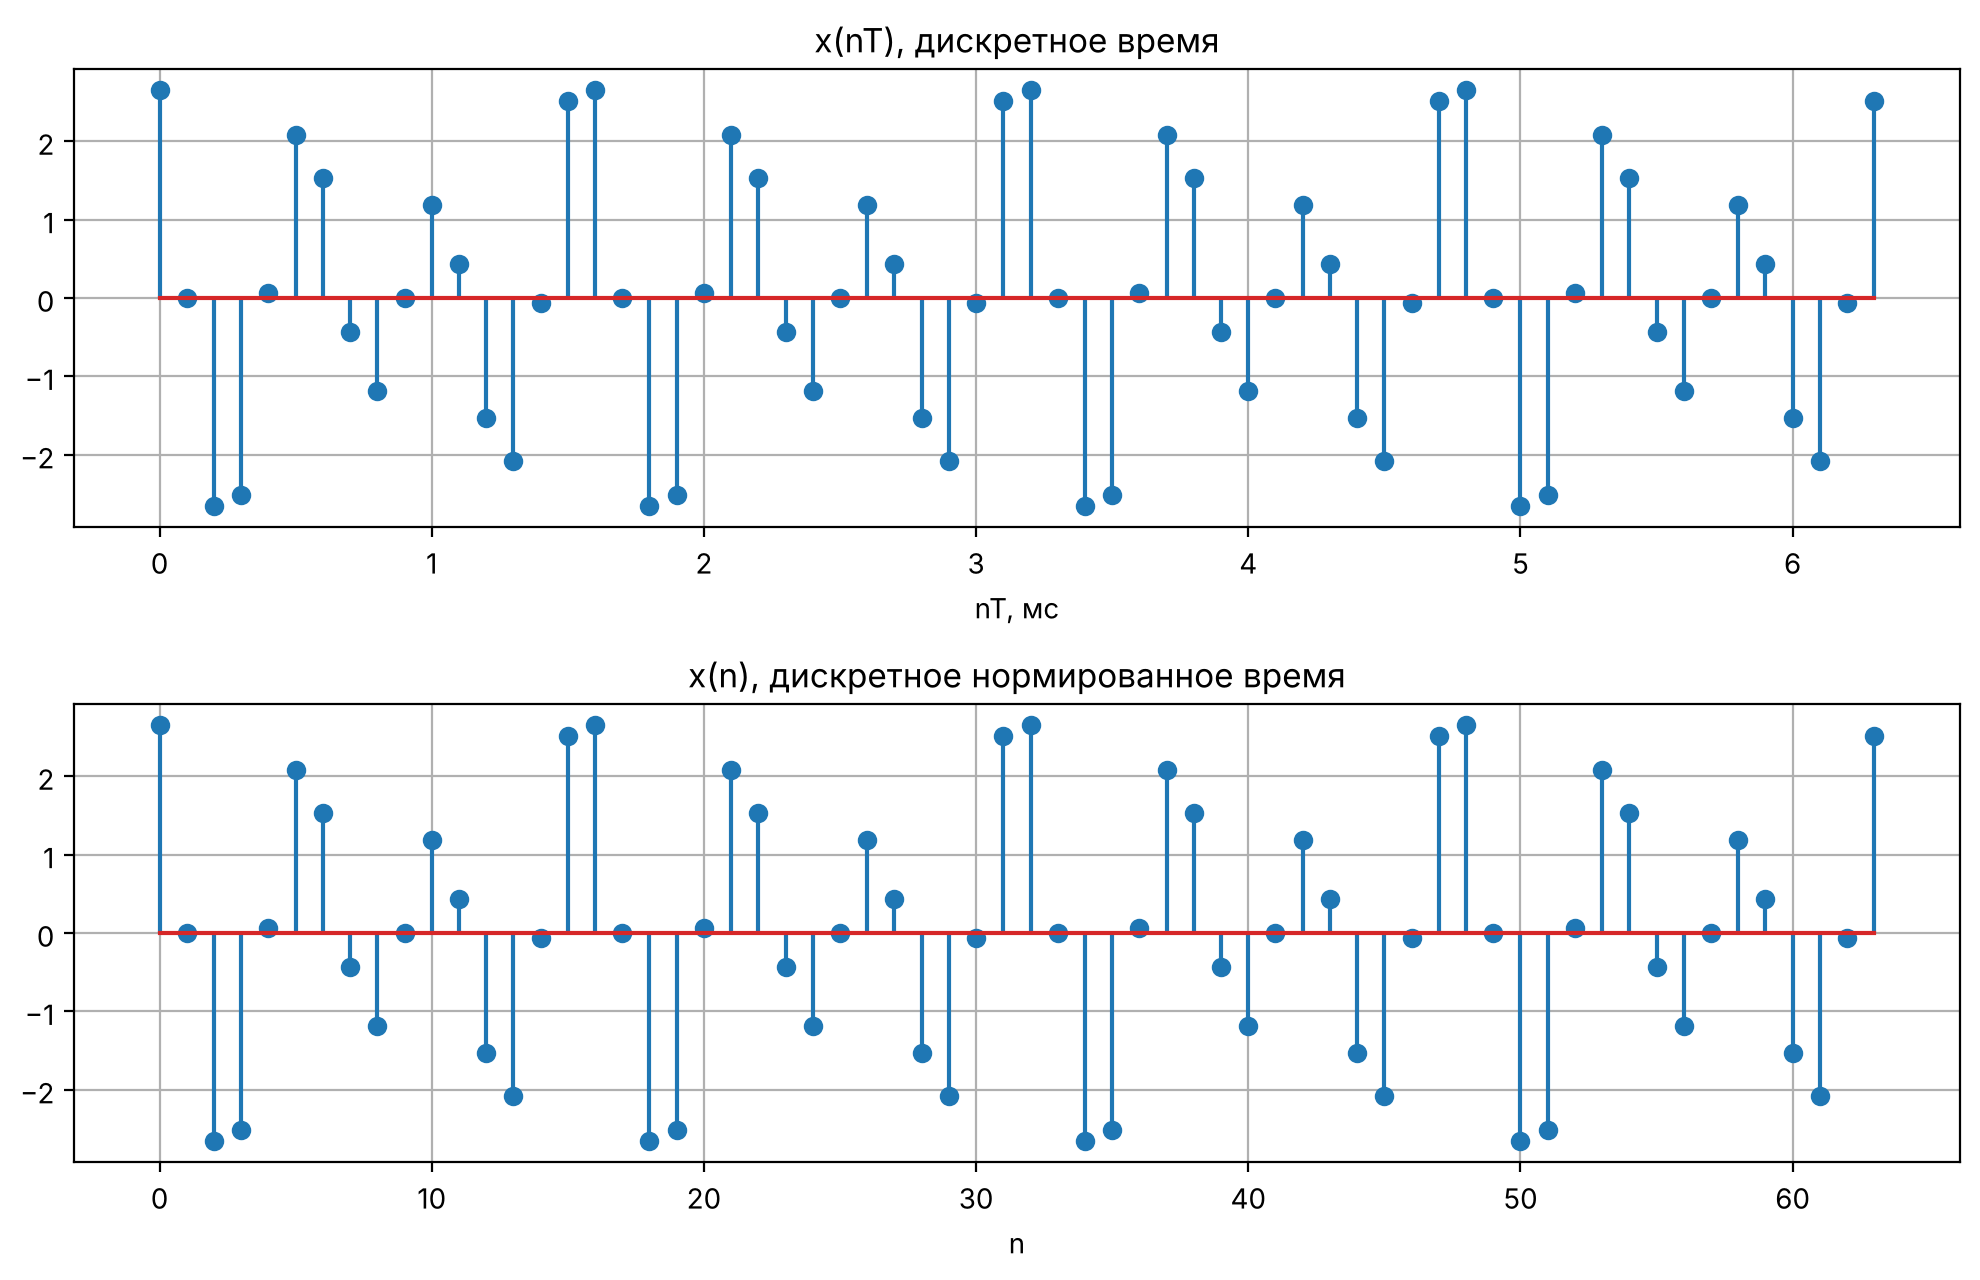

In [12]:
n = np.arange(N)
xs = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi / 8)

fig, ax = plt.subplots(2, 1, figsize=(10, 6.5))
ax[0].stem(n * T * 1000, xs)
ax[0].set_title('x(nT), дискретное время')
ax[0].set_xlabel('nT, мс')
ax[1].stem(n, xs)
ax[1].set_title('x(n), дискретное нормированное время')
ax[1].set_xlabel('n')
plt.tight_layout()
plt.show()

### Пункт 2. ОДПФ от ДПФ

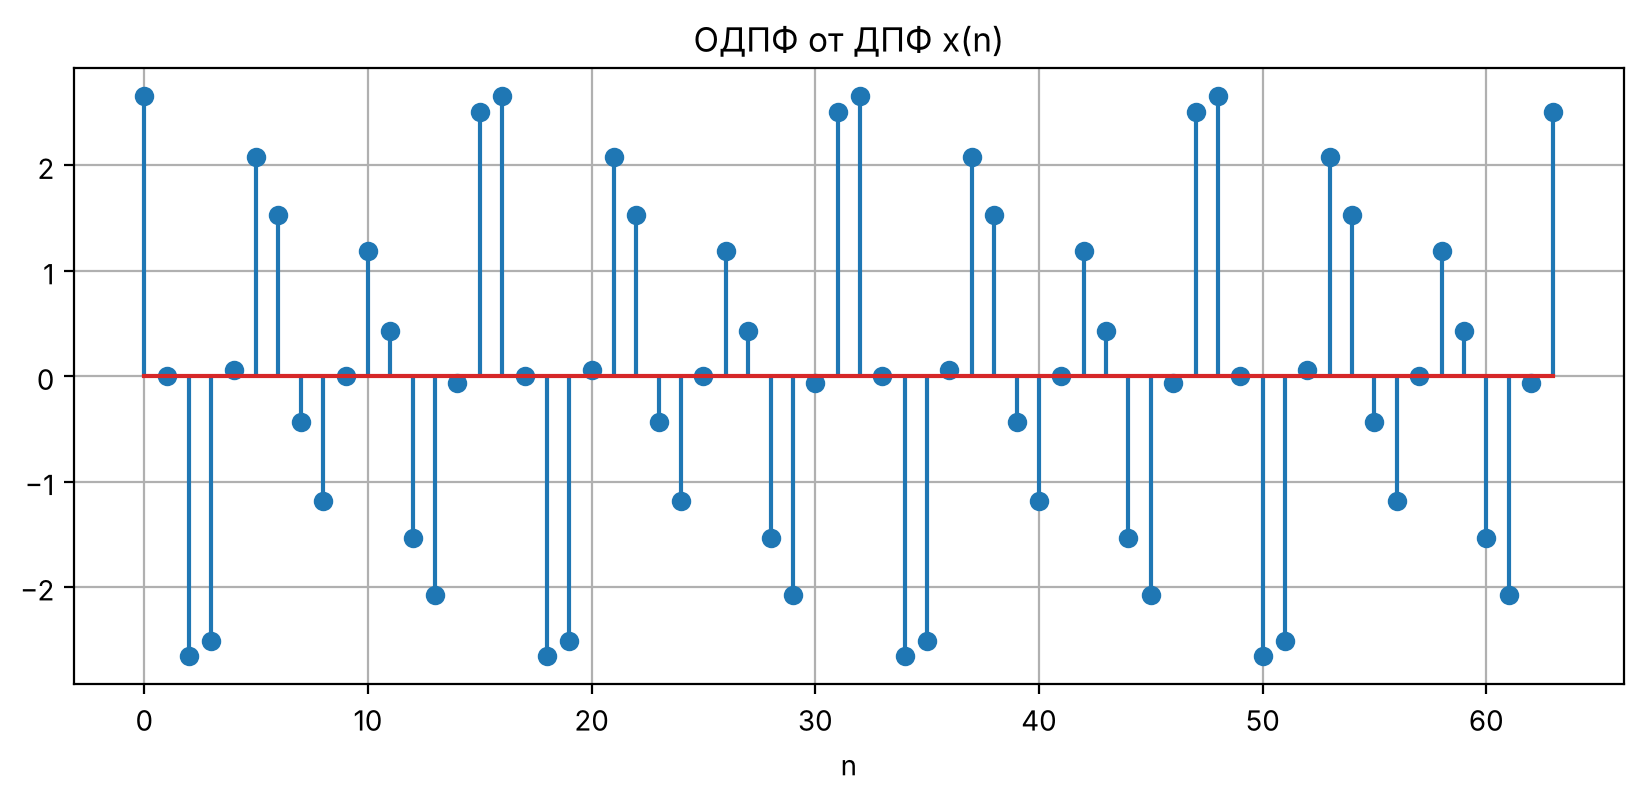

True


In [13]:
X = np.fft.fft(xs)
x_obr = np.fft.ifft(X).real

plt.stem(n, x_obr)
plt.title('ОДПФ от ДПФ x(n)')
plt.xlabel('n')
plt.show()

print(np.allclose(x_obr, xs))

Получилась исходная последовательность.

### Пункт 3. Амплитудный и фазовый спектры

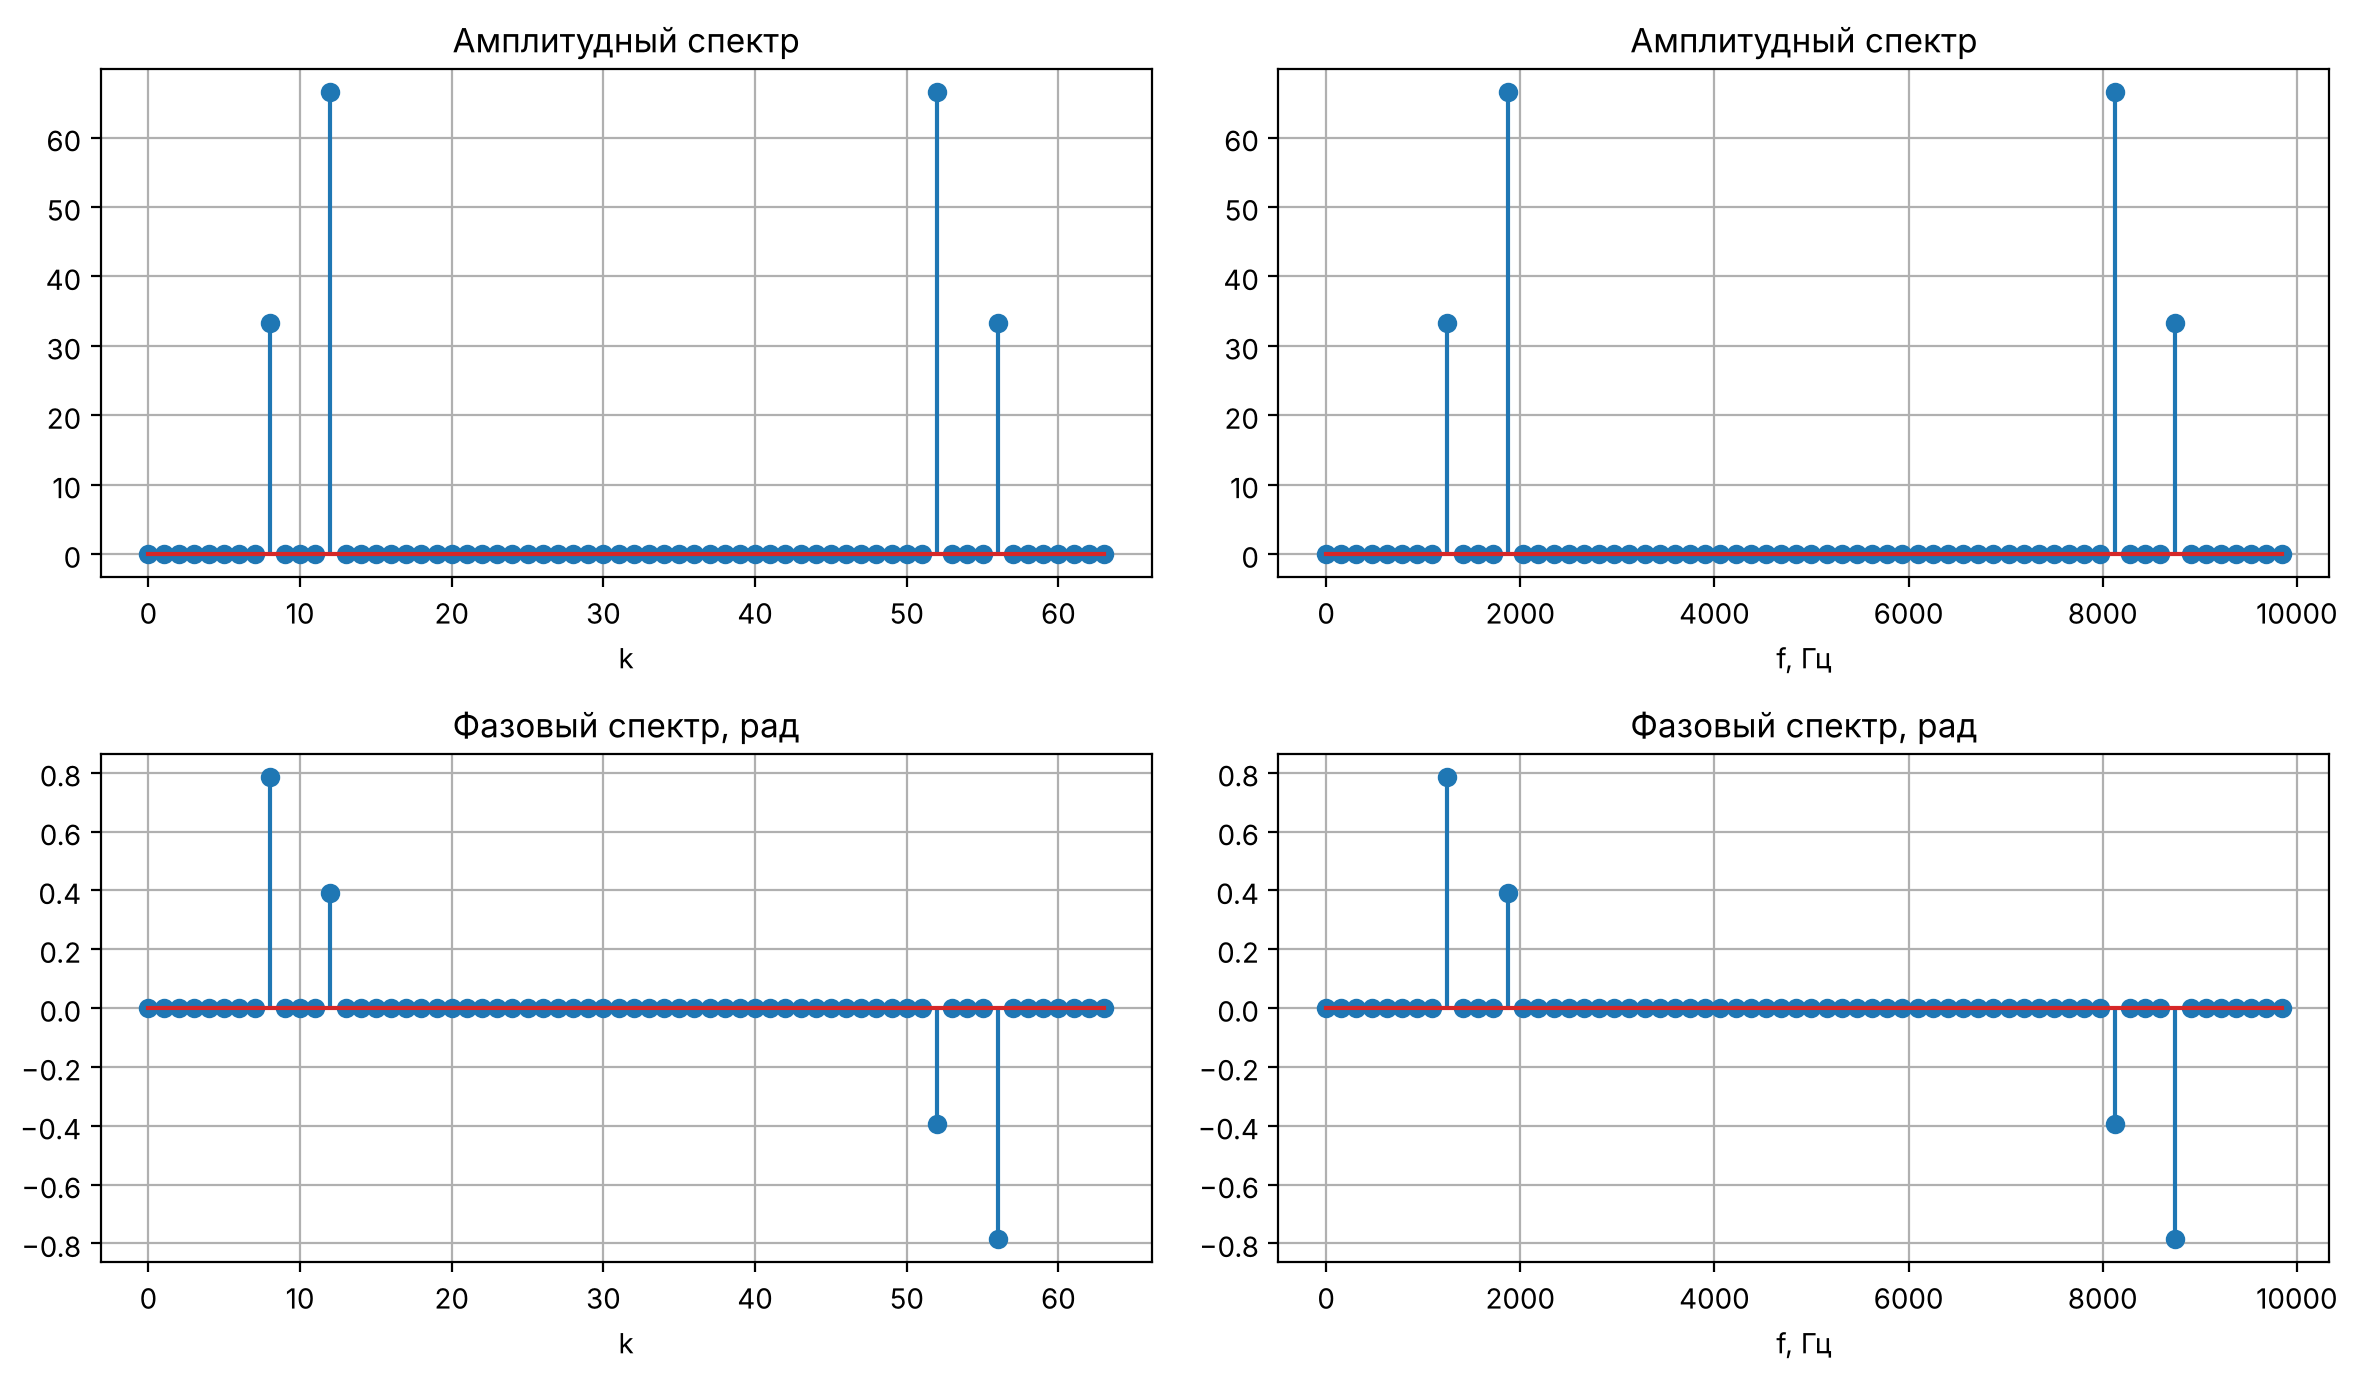

k = 8  f = 1250.0  |X| = 33.28  arg = 0.25 pi
k = 12  f = 1875.0  |X| = 66.56  arg = 0.125 pi
k = 52  f = 8125.0  |X| = 66.56  arg = -0.125 pi
k = 56  f = 8750.0  |X| = 33.28  arg = -0.25 pi


In [14]:
k = np.arange(N)
ff = k * fd2 / N
Xm = abs(X)
Xf = np.angle(X)
Xf[Xm < 1e-8] = 0   # где |X| почти 0, фазу обнуляем

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].stem(k, Xm)
ax[0, 0].set_title('Амплитудный спектр')
ax[0, 0].set_xlabel('k')
ax[1, 0].stem(k, Xf)
ax[1, 0].set_title('Фазовый спектр, рад')
ax[1, 0].set_xlabel('k')
ax[0, 1].stem(ff, Xm)
ax[0, 1].set_title('Амплитудный спектр')
ax[0, 1].set_xlabel('f, Гц')
ax[1, 1].stem(ff, Xf)
ax[1, 1].set_title('Фазовый спектр, рад')
ax[1, 1].set_xlabel('f, Гц')
plt.tight_layout()
plt.show()

for i in range(N):
    if Xm[i] > 1e-8:
        print('k =', i, ' f =', ff[i], ' |X| =', round(Xm[i], 2), ' arg =', round(Xf[i] / np.pi, 3), 'pi')

а) $n=nT/T$, то есть $n$ показывает номер отсчета, а $nT$ время в секундах (шаг $T=0.1$ мс).

б) $f=k\,f_д/N$, шаг по частоте $f_д/N=156.25$ Гц.

в) В спектре 4 ненулевых отсчета: $k=8$ и $k=12$ (1250 и 1875 Гц) и симметричные им $k=56$ и $k=52$. Их значения 33.28 и 66.56, то есть $NA_1/2$ и $NA_2/2$. Амплитудный спектр симметричен относительно $k=N/2$, фазовый антисимметричен. На $k=8$ фаза $\pi/4$, на $k=12$ фаза $\pi/8$, на $k=56$ и $k=52$ те же значения с минусом. Остальные отсчеты нулевые, потому что частоты гармоник попадают точно на $k=8$ и $k=12$.

### Пункт 4. ДПФ конечной последовательности

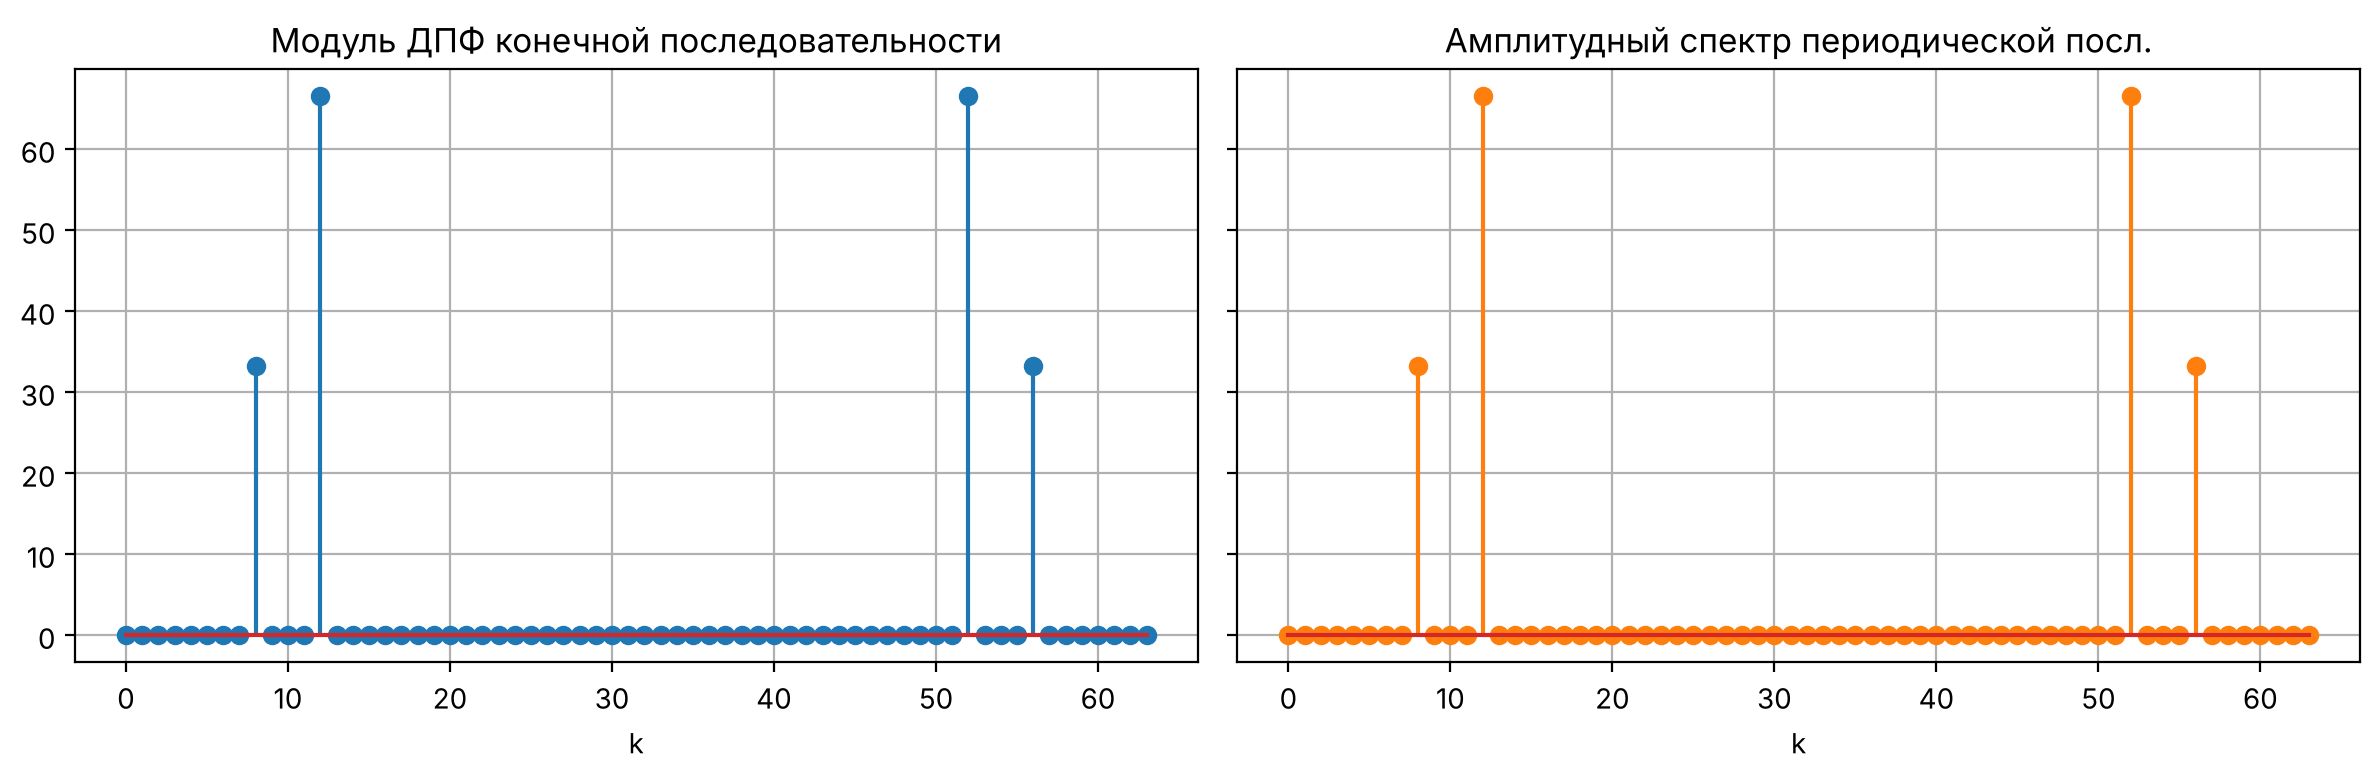

In [15]:
X2 = np.fft.fft(xs)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].stem(k, abs(X2))
ax[0].set_title('Модуль ДПФ конечной последовательности')
ax[0].set_xlabel('k')
ax[1].stem(k, Xm, linefmt='C1-', markerfmt='C1o')
ax[1].set_title('Амплитудный спектр периодической посл.')
ax[1].set_xlabel('k')
plt.tight_layout()
plt.show()

Графики одинаковые. Конечная последовательность длины $N$ совпадает с одним периодом периодической, поэтому и ДПФ у них одно и то же. Для конечной последовательности это отсчеты ее непрерывного спектра в точках $\hat\omega=2\pi k/N$, для периодической это ее амплитудный спектр.

### Пункт 5. Восстановление аналогового сигнала

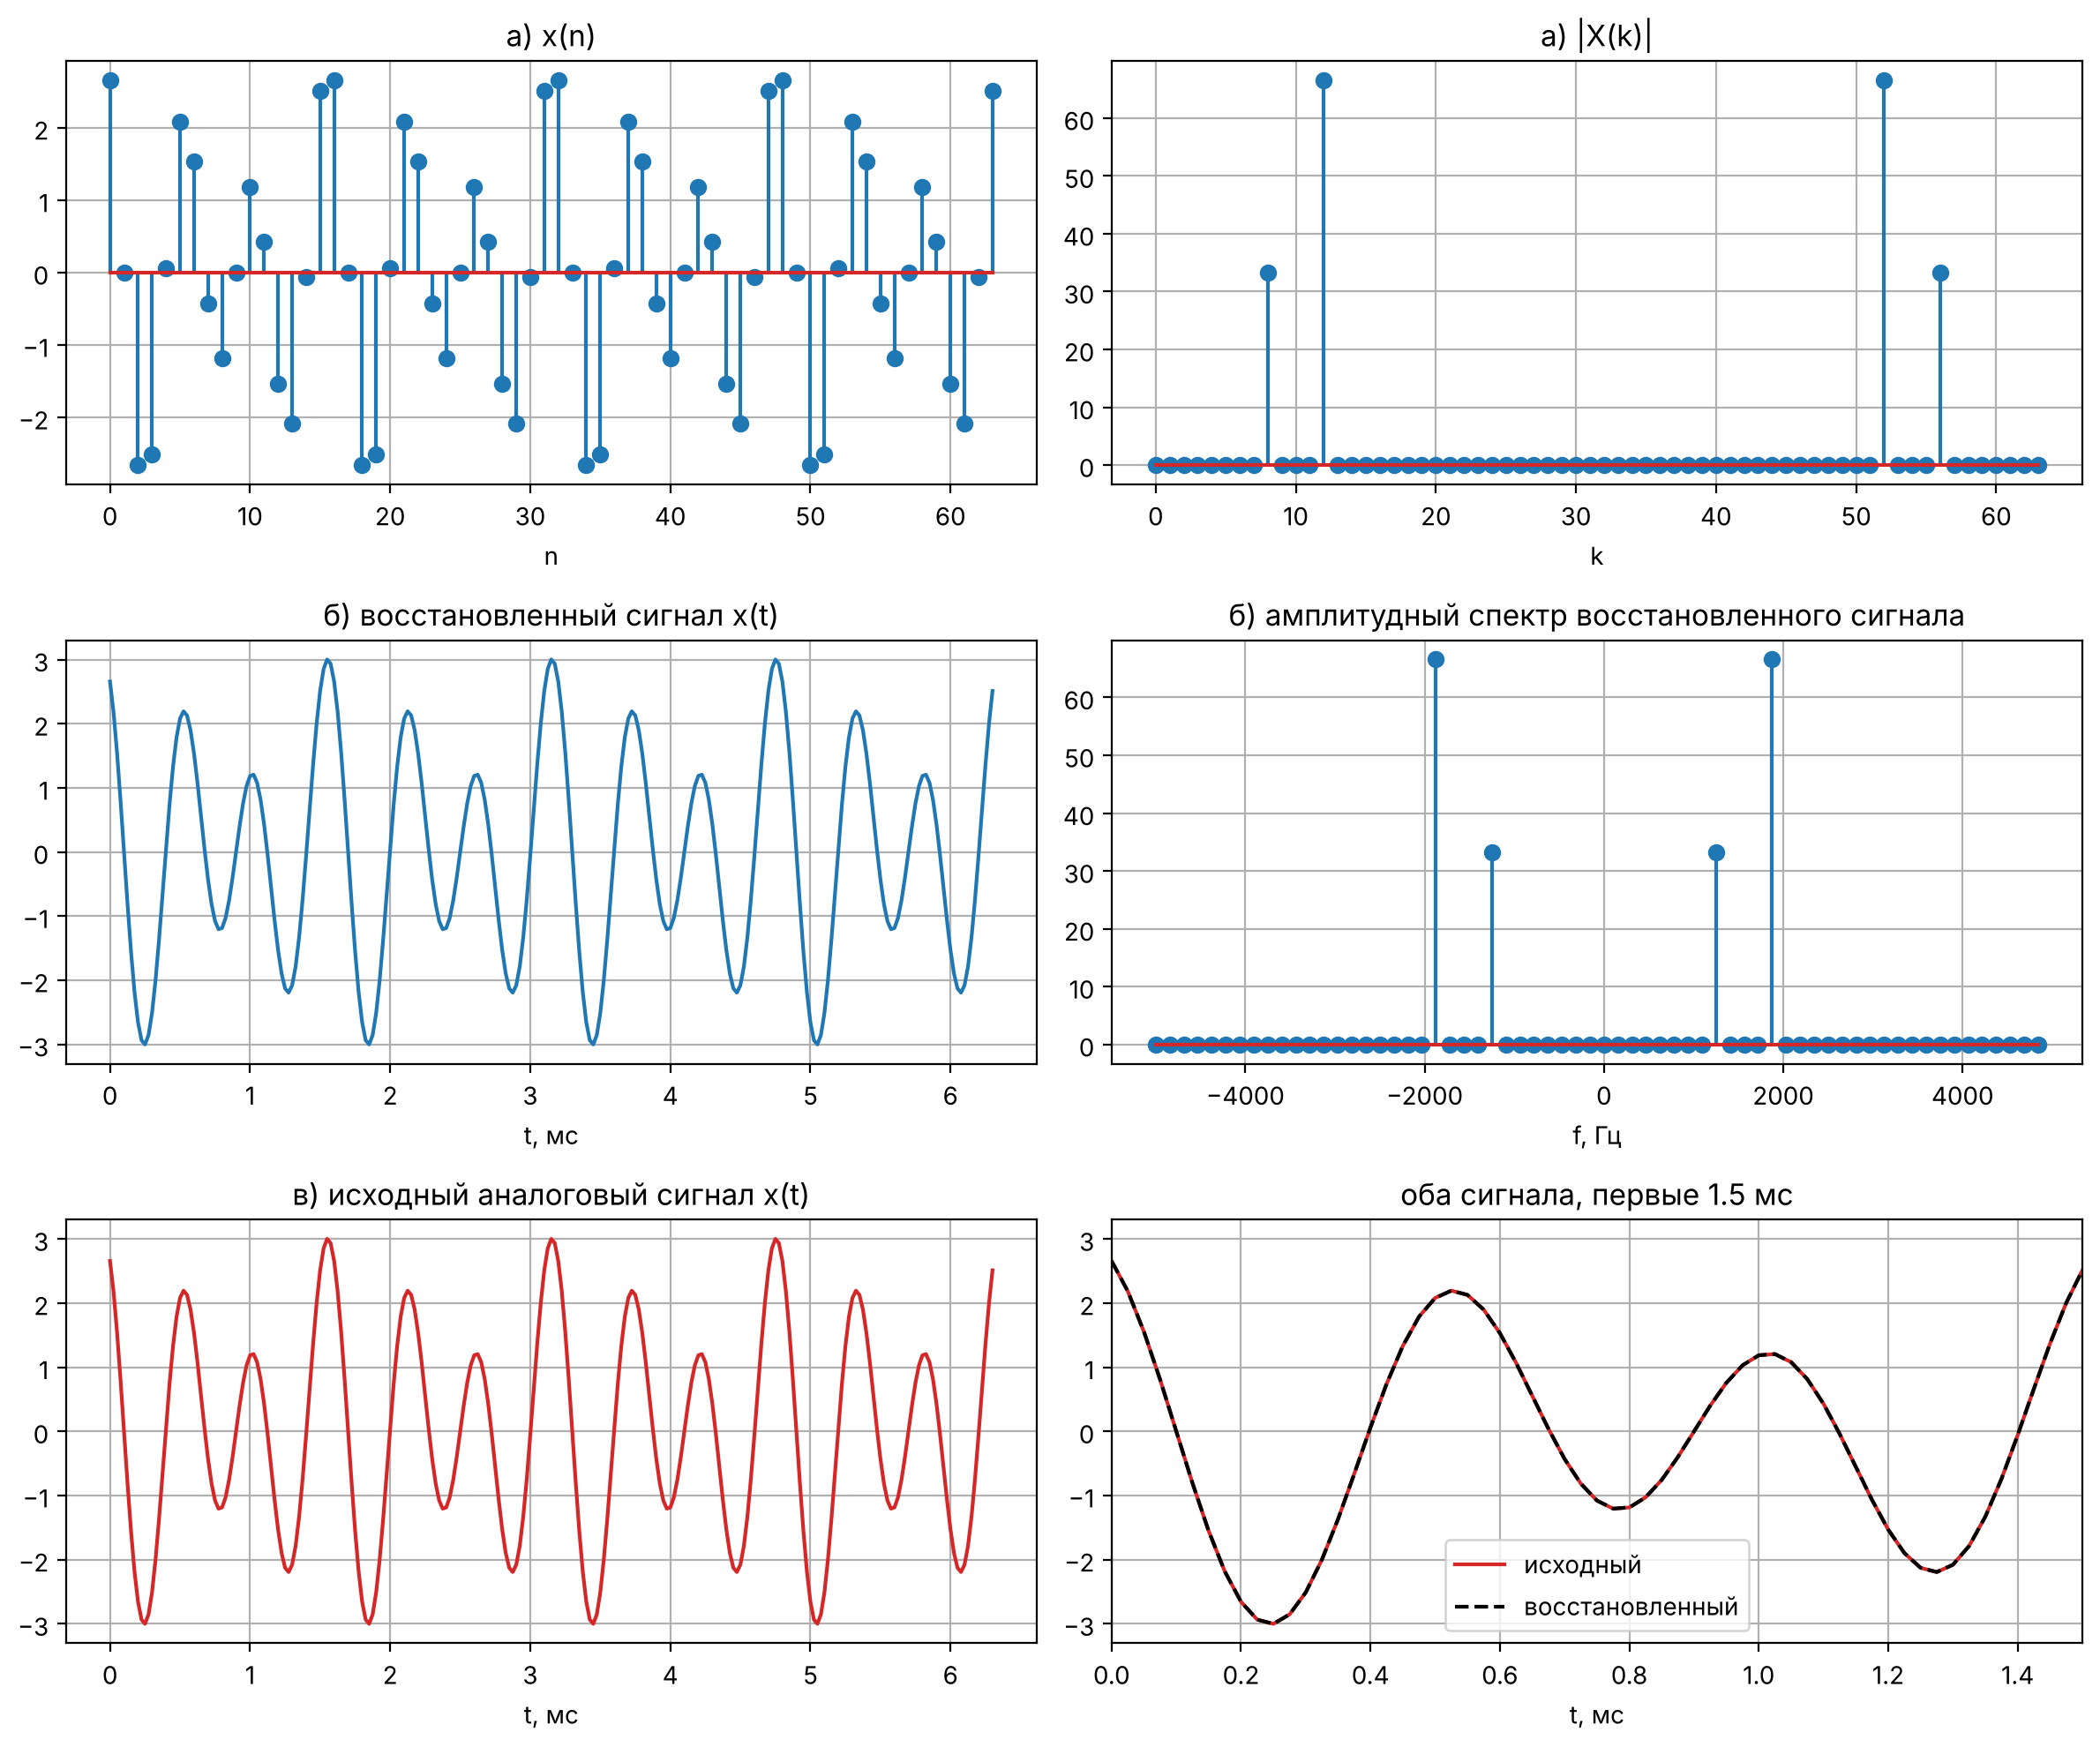

True


In [16]:
kk = np.arange(-N // 2, N // 2)
Xa = np.zeros(N, dtype=complex)
for i in range(N):
    if kk[i] < 0:
        Xa[i] = X[N + kk[i]]
    else:
        Xa[i] = X[kk[i]]

dt = 0.25 * T
t = np.arange(0, (N - 1) * T + dt / 2, dt)

xt = np.zeros(len(t), dtype=complex)
for i in range(N):
    xt = xt + Xa[i] * np.exp(1j * 2 * np.pi * kk[i] * t / (N * T))
xt = xt.real / N

x_ish = A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

fa = kk / (N * T)

fig, ax = plt.subplots(3, 2, figsize=(12, 10))
ax[0, 0].stem(n, xs)
ax[0, 0].set_title('а) x(n)')
ax[0, 0].set_xlabel('n')
ax[0, 1].stem(k, Xm)
ax[0, 1].set_title('а) |X(k)|')
ax[0, 1].set_xlabel('k')
ax[1, 0].plot(t * 1000, xt)
ax[1, 0].set_title('б) восстановленный сигнал x(t)')
ax[1, 0].set_xlabel('t, мс')
ax[1, 1].stem(fa, abs(Xa))
ax[1, 1].set_title('б) амплитудный спектр восстановленного сигнала')
ax[1, 1].set_xlabel('f, Гц')
ax[2, 0].plot(t * 1000, x_ish, color='C3')
ax[2, 0].set_title('в) исходный аналоговый сигнал x(t)')
ax[2, 0].set_xlabel('t, мс')
ax[2, 1].plot(t * 1000, x_ish, color='C3', label='исходный')
ax[2, 1].plot(t * 1000, xt, 'k--', label='восстановленный')
ax[2, 1].set_xlim(0, 1.5)
ax[2, 1].set_title('оба сигнала, первые 1.5 мс')
ax[2, 1].set_xlabel('t, мс')
ax[2, 1].legend()
plt.tight_layout()
plt.show()

print(np.allclose(xt, x_ish))

### Пункт 6

а) Если отсчеты ДПФ с $k\geq N/2$ перенести в отрицательные частоты ($k-N$), то модуль ДПФ совпадает с амплитудным спектром аналогового сигнала с точностью до множителя $N$: линии на $\pm1250$ и $\pm1875$ Гц. Так получается, потому что выполняется теорема Котельникова ($1875<5000$ Гц) и на длине $N$ укладывается целое число периодов обеих гармоник.

б) Восстановленный и исходный сигналы совпадают.

### Пункт 7. Равенство Парсеваля

$$\sum_{n=0}^{N-1}|x(n)|^2=\frac1N\sum_{k=0}^{N-1}|X(k)|^2$$

In [17]:
s1 = sum(xs**2)
s2 = sum(abs(X)**2) / N
print(s1)
print(s2)

173.05600000000004
173.05600000000007


Обе суммы равны 173.056, равенство выполняется. Это значит, что энергия сигнала одна и та же, считать ее по отсчетам сигнала или по отсчетам ДПФ.